In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Import Dataset:

In [2]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(url)

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


Data preparation

In [3]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [5]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Split the data

In [6]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [7]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del df_train['converted']
del df_val['converted']
del df_test['converted']

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

1. ROC AUC feature importance

In [8]:
from sklearn.metrics import roc_auc_score

for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print(f"{c}: {auc:.4f}")

annual_income: 0.6082
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
lead_score: 0.7882


2. Training the model

In [9]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

features = categorical + numerical

dv = DictVectorizer(sparse=False)

train_dict = df_train[features].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[features].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [10]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

auc, round(auc, 3)

(0.7318222288173319, 0.732)

3. Precision and Recall

In [11]:
def precision_recall(y_true, y_score, t):
    predict_positive = (y_score >= t)
    actual_positive = (y_true == 1)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & ~actual_positive).sum()
    fn = (~predict_positive & actual_positive).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    return p, r

In [12]:
thresholds = np.arange(0.0, 1.01, 0.01)

scores = []

for t in thresholds:
    p, r = precision_recall(y_val, y_pred, t)
    scores.append((t, p, r))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

df_scores.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


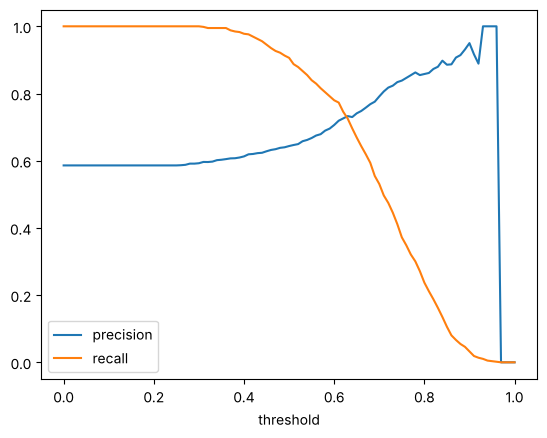

In [13]:
plt.plot(df_scores['threshold'], df_scores['precision'], label='precision')
plt.plot(df_scores['threshold'], df_scores['recall'], label='recall')

plt.xlabel('threshold')
plt.legend()
plt.show()

In [14]:
valid = df_scores[(df_scores['precision'] > 0) | (df_scores['recall'] > 0)].copy()

valid['diff'] = (valid['precision'] - valid['recall']).abs()

valid.sort_values('diff').head()

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


In [15]:
best = valid.loc[valid['diff'].idxmin()]

round(best['threshold'], 2)

np.float64(0.63)

4. F1 score

In [16]:
df_scores['f1'] = 2 * df_scores['precision'] * df_scores['recall'] / (df_scores['precision'] + df_scores['recall'])

df_scores['f1'] = df_scores['f1'].fillna(0.0)

df_scores.sort_values('f1', ascending=False).head()

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
45,0.45,0.628118,0.945392,0.754768
44,0.44,0.623608,0.955631,0.754717


In [17]:
round(df_scores.loc[df_scores['f1'].idxmax(), 'threshold'], 2)

np.float64(0.41)

5. 5-Fold CV

In [18]:
from sklearn.model_selection import KFold

def train(df_tr, y_tr, C=1.0):
    dicts = df_tr[features].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)

    return dv, model


def predict(df_va, dv, model):
    dicts = df_va[features].to_dict(orient='records')
    X = dv.transform(dicts)

    return model.predict_proba(X)[:, 1]

In [19]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    y_tr = df_tr['converted'].values
    y_va = df_va['converted'].values

    dv, model = train(df_tr, y_tr)
    y_hat = predict(df_va, dv, model)

    scores.append(roc_auc_score(y_va, y_hat))

scores

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [20]:
print(f"mean={np.mean(scores):.4f}, std={np.std(scores):.4f}")

mean=0.7317, std=0.0069


6. Hyperparameter Tuning

In [21]:
for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr['converted'].values
        y_va = df_va['converted'].values

        dv, model = train(df_tr, y_tr, C=C)
        y_hat = predict(df_va, dv, model)

        scores.append(roc_auc_score(y_va, y_hat))

    print(f"C={C}: mean={np.mean(scores):.3f}, std={np.std(scores):.3f}")

C=1e-06: mean=0.617, std=0.019


C=0.001: mean=0.749, std=0.010


C=1: mean=0.732, std=0.007
